# Task 1
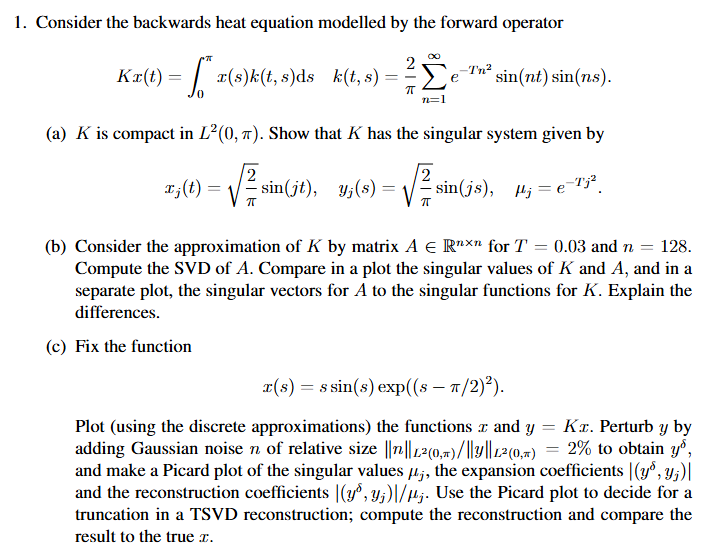

In [76]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from IPython.core.magic import register_cell_magic

OUTPUT_DIR = Path("./output")
OUTPUT_DIR.mkdir(exist_ok=True)

PAPER_WIDTH_IN = 6.7  # Inches, 170mm

sns.set_theme(context="paper", style="whitegrid")

# Magic command to export to file
@register_cell_magic
def write_and_run(line, cell):
    argz = line.split()
    file = argz[-1]
    mode = "w"
    if len(argz) == 2 and argz[0] == "-a":
        mode = "a"
    with open(file, mode, encoding="UTF-8") as f:
        f.write(cell)
    get_ipython().run_cell(cell)

## 1.b
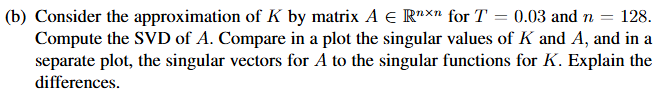

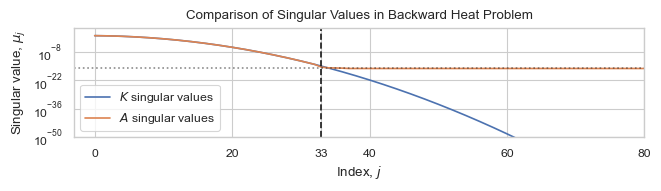

<Figure size 640x480 with 0 Axes>

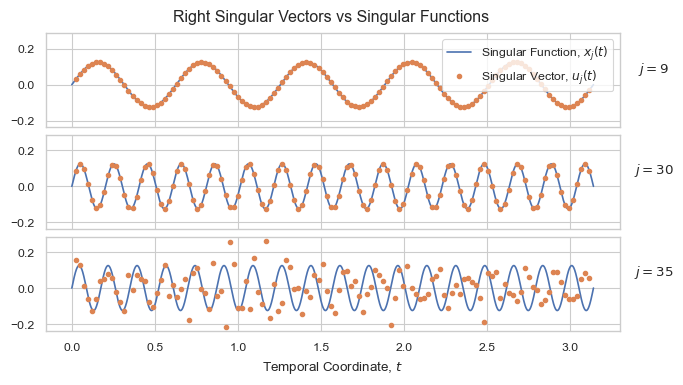

In [84]:
%%write_and_run output/1_b.py
T = 0.03
n = 128

k = np.arange(1, n + 1)
t = k * np.pi / (n+1)
s = k * np.pi / (n+1)

# We construct A matrix using spectral method
# Alternative would be to use a quadrature rule

# Create left and right singular vectors sampled at t_i, s_i
j = np.arange(1, n + 1)
U = np.sqrt(2/(n+1)) * np.sin(np.einsum('i,j->ij', t, k))
V = np.sqrt(2/(n+1)) * np.sin(np.einsum('i,j->ij', s, k))
assert np.allclose(U.T @ U, np.eye(n)), "V is not orthogonal"
assert np.allclose(V.T @ V, np.eye(n)), "V is not orthogonal"

# Create diagonal matrix S of singular values
S = np.diag(np.exp(-j**2 * T))

# Now we can construct A = U D V^*
A = U @ S @ V.T

# Now we can compare as requested in assignment
# This is almost cheating since we constructed A from its SVD
# But it would yield the same results if constructed using a sufficiently
# accurate quadrature rule
U_svd, S_svd, Vh_svd = np.linalg.svd(A)
plt.figure(figsize=(PAPER_WIDTH_IN, 2.0))
plt.plot(np.diagonal(S), label='$K$ singular values')
plt.plot(S_svd, label='$A$ singular values')
plt.axvline(33, color='k', ls='--')
plt.axhline(1e-16, color='k', ls=':', alpha=0.5)
plt.xticks(list(plt.xticks()[0]) + [33])
plt.semilogy()
plt.title("Comparison of Singular Values in Backward Heat Problem")
plt.xlabel("Index, $j$")
plt.ylabel("Singular value, $μ_j$")
plt.legend()
plt.ylim(1e-50, 1e4)
plt.xlim(0-3, 80)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_b_singular_values.png", dpi=600, bbox_inches='tight')

# Singular vectors vs functions
plt.figure()
def singular_vector_func(j, x):
    return np.sqrt(2/np.pi) * np.sin(j * np.pi * x)

t_i_fine = np.linspace(0, np.pi, 2500)
fig, axes = plt.subplots(3, 1, figsize=(PAPER_WIDTH_IN, 4), sharex=True, sharey=True)
for i, (ax, j_k) in enumerate(zip(axes, [9, 30, 35])):
    u_calculated = singular_vector_func(j_k + 1, t_i_fine / np.pi)
    u_calculated *= np.sqrt(t[1]-t[0])  # Normalization factor
    ax.plot(t_i_fine, u_calculated, label=f'Singular Function, $x_j(t)$')
    ax.plot(t, U_svd[:, j_k], "o", ms=3, label='Singular Vector, $u_j(t)$')
    ax.set_title(f"$j={j_k}$", x=1.06, y=0.5)

    if i == 0:
        ax.legend()

    if i == 2:
        ax.set_xlabel("Temporal Coordinate, $t$")

fig.suptitle("Right Singular Vectors vs Singular Functions", y=0.95)
fig.tight_layout()
fig.subplots_adjust(hspace=0.08)
fig.savefig(OUTPUT_DIR / "1_b_singular_vectors.png", dpi=600, bbox_inches='tight')

## 1.c
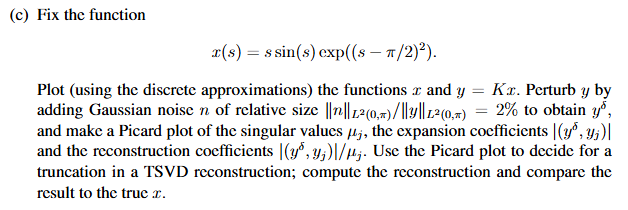

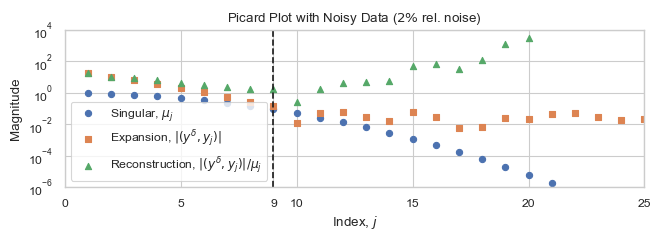

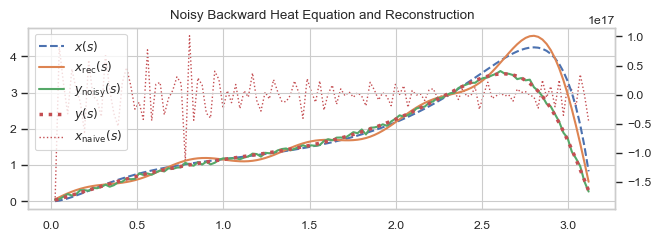

In [ ]:
%%write_and_run output/1_c.py
np.random.seed(42)

def x_func(s):
    return s * np.sin(s) * np.exp((s - np.pi / 2)**2)

x = x_func(s)
y = A @ x
unscaled_noise = np.random.randn(*y.shape)
unscaled_noise_level = np.linalg.norm(unscaled_noise)
noise_coeff = 0.02 * np.linalg.norm(y) / unscaled_noise_level
noise = noise_coeff * unscaled_noise
y_noisy = y + noise
x_naive = np.linalg.inv(A) @ y_noisy

# Prepare for Picard plot
singular_values = np.diagonal(S)
expansion_coefficients = np.abs(U.T @ y_noisy)
reconstruction_coefficients = expansion_coefficients / singular_values
plt.figure(figsize=(PAPER_WIDTH_IN, 2.5))
plt.scatter(j, singular_values, marker="o", s=20, label='Singular, $μ_j$')
plt.scatter(j, expansion_coefficients, marker="s", s=20, label='Expansion, $|(y^δ, y_j)|$')
plt.scatter(j, reconstruction_coefficients, marker="^", s=20, label='Reconstruction, $|(y^δ, y_j)|/μ_j$')
plt.semilogy()
plt.legend()
plt.xlim(0, 25)
plt.ylim(1e-6, 1e4)
plt.axvline(9, color='k', ls='--')
plt.xticks(list(plt.xticks()[0]) + [9])
plt.title("Picard Plot with Noisy Data ($2\\%$ rel. noise)")
plt.xlabel("Index, $j$")
plt.ylabel("Magnitude")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c_picard_plot.png", dpi=600, bbox_inches='tight')

# Compute reconstruction
j_cutoff = 9  # Inclusive
S_truncated = S[:j_cutoff, :j_cutoff]
U_truncated = U[:, :j_cutoff]
V_truncated = V.T[:, :j_cutoff]
K_inv_truncated = V_truncated @ np.linalg.inv(S_truncated) @ U_truncated.T
x_reconstructed = K_inv_truncated @ y_noisy

plt.figure(figsize=(PAPER_WIDTH_IN, 2.5))
plt.plot(s, x_func(s), label='$x(s)$', ls="--", lw=1.5)
plt.plot(s, x_reconstructed, label='$x_\\text{rec}(s)$', lw=1.5)
plt.plot(s, y_noisy, label='$y_\\text{noisy}(s)$', lw=1.5)
plt.plot(s, y, label='$y(s)$', ls=":", lw=2.5)
plt.legend()

# Create new axis for naive solution
ax_main = plt.gca()
ax_noisy = plt.twinx()
ax_noisy.plot(s, x_naive, label='$x_\\text{naive}(s)$', color='C3', ls=":", lw=1)
ax_noisy.grid(False)
ax_main.set_zorder(1)
ax_main.patch.set_visible(False)

# Merge legends
handles1, labels1 = ax_main.get_legend_handles_labels()
handles2, labels2 = ax_noisy.get_legend_handles_labels()
ax_main.legend(handles1 + handles2, labels1 + labels2, loc='upper left')

plt.xlabel("Spatial Coordinate, $s$")
plt.title("Noisy Backward Heat Equation and Reconstruction")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "1_c_reconstruction.png", dpi=600, bbox_inches='tight')